# SPP Parameter Misspecification Study

## Objective

The parametric formulation assumes that the environment force belongs to a prescribed functional family. While this assumption can improve recovery when the correct functional form is known, it may also introduce model bias when the chosen basis is misspecified.

This notebook investigates this limitation using the SPP system.

## Experimental Setup

The training trajectories, interaction-kernel basis, solver settings, and learning procedure are identical to those used in the standard SPP experiment.

The only modification is the choice of parametric basis used to represent the environment force \(f(v)\). Instead of the basis employed in the reference experiment, we use the alternative basis

\[
\texttt{parametric\_f\_basis2},
\]

defined in

```text
src/ips_learning/systems/spp.py
```

to intentionally introduce model misspecification.

## Workflow

1. Load the original SPP training dataset.
2. Construct the interaction-kernel basis and the misspecified parametric basis.
3. Fit the parametric model.
4. Save the fitted coefficients and diagnostics.
5. Generate reconstructed and predictive trajectories.
6. Compare the learned interaction kernel against the true kernel.
7. Compare the learned environment force against the true environment force.
8. Evaluate trajectory-level performance.
9. Visualize the resulting degradation caused by basis misspecification.

## Expected Outcome

If the assumed parametric family does not contain the true environment force, the learned force field should exhibit systematic errors even when the interaction kernel is recovered accurately.

This experiment demonstrates a key limitation of parametric learning: high accuracy depends on selecting a sufficiently expressive and correctly specified model class.

```
artifacts/
└── spp/
    └── limitation/
        └── parameter_misspecification/
            ├── fits/
            │   └── parametric_f_basis2/
            │       └── metadata.json
            ├── rollouts/
            ├── figures/
            ├── tables/
            ├── evaluations/
            └── metadata.json'''






                


```
artifacts/
├── fits/
│   └── spp/
│       └── limitation/
│           └── parametric_f/
│               └── parametric_f_basis2/
└── rollouts/
    └── spp/
        └── limitation/
            └── parametric_f/
                └── parametric_f_basis2/```

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import os

def find_project_root(start: Path) -> Path:
    current = start.resolve()

    while current != current.parent:
        if (current / "src").exists() and (current / "artifacts").exists():
            return current
        if (current / "src").exists():
            return current
        current = current.parent

    raise RuntimeError("Could not locate project root containing src/")


PROJECT_ROOT = find_project_root(Path.cwd())

SRC = PROJECT_ROOT / "src"
ARTIFACTS = PROJECT_ROOT / "artifacts"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("SRC:", SRC)
print("ARTIFACTS:", ARTIFACTS)


#-------------------
# Change working directory to project root
os.chdir(PROJECT_ROOT)
print("CWD:", Path.cwd())

PROJECT_ROOT: .
SRC: ./src
ARTIFACTS: ./artifacts
CWD: .


In [2]:
SYSTEM_NAME = "spp"


# Original data profile
DATA_PROFILE_NAME = "spp_velocity_grid_clumps"

# Artifact namespace for the limitation experiment.
PROFILE_NAME = "limitation"
TASK_NAME = "parameter_misspecification"
EXPERIMENT_PROFILE_NAME = f"{PROFILE_NAME}/{TASK_NAME}"

CASE_NAME = "parametric_f_basis2"

TRIAL = 1
SYSTEM_ORDER = 2
INTERACTION_TYPE = "energy"

TRAIN_SPLIT = "train"
TRAIN_FIT_SPLIT = "train_fit"
TEST_SPLIT = "test"
KDE_SPLIT = "kde"

TRAIN_DATASET_NAME = f"dataset_train_trial_{TRIAL:03d}"
TRAIN_FIT_DATASET_NAME = f"dataset_train_fit_trial_{TRIAL:03d}"
TEST_DATASET_NAME = "dataset_test"
KDE_DATASET_NAME = "dataset_kde"

FIT_END_TIME = 0.5
PREDICTION_END_TIME = 2.0

FIT_CASE_NAME = CASE_NAME
FEATURE_NAME = TRAIN_FIT_DATASET_NAME
BASIS_NAME =f"{TASK_NAME}_{CASE_NAME}_{TRAIN_FIT_DATASET_NAME}"

TASK_DIR = ARTIFACTS / SYSTEM_NAME / PROFILE_NAME / TASK_NAME
FIGURE_DIR = TASK_DIR / "figures"
TABLE_DIR = TASK_DIR / "tables"
EVAL_DIR = TASK_DIR / "evaluations"
LOCAL_FIT_DIR = TASK_DIR / "fits" / CASE_NAME
LOCAL_ROLLOUT_DIR = TASK_DIR / "rollouts"

for path in [TASK_DIR, FIGURE_DIR, TABLE_DIR, EVAL_DIR]:
    path.mkdir(parents=True, exist_ok=True)

In [3]:
EXPERIMENT_METADATA = {
    "system_name": "spp",
    "profile_name": "limitation",
    "task_name": "parameter_misspecification",
    "case_name": "parametric_f_basis2",
    "algorithm": "parametric_f",
    "purpose": (
        "Demonstrate degradation caused by "
        "misspecified environment-force basis."
    ),
}
with open(TASK_DIR / "metadata.json", "w") as f:
    json.dump(EXPERIMENT_METADATA, f, indent=2)

In [4]:
from ips_learning.data.dataset_repository import DatasetRepository
from ips_learning.features.feature_builder import FeatureBuilder
from ips_learning.features.feature_repository import FeatureRepository
from ips_learning.bases.specs import BasisConfig, RadialBasisSpec, EnvironmentBasisSpec
from ips_learning.bases.builders import BasisBuilder
from ips_learning.bases.repository import BasisRepository
from ips_learning.fitting.assembler import NormalEquationAssembler
from ips_learning.fitting.solver import LinearSystemSolver
from ips_learning.fitting.system_repository import NormalSystemRepository
from ips_learning.models.factories import LearnedModelFactory
from ips_learning.rollout.simulator import LearnedSystemRollout
from ips_learning.rollout.repository import RolloutRepository

from ips_learning.systems.spp import parametric_f_basis2
from ips_learning.statistics.density import build_empirical_error_density


In [5]:
dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")
feature_repo = FeatureRepository(root_dir=ARTIFACTS / "features")
basis_repo = BasisRepository(root_dir=ARTIFACTS / "bases")
fit_repo = NormalSystemRepository(root_dir=ARTIFACTS / "fits")
rollout_repo = RolloutRepository(root_dir=ARTIFACTS / "rollouts")

In [6]:
# General helper functions

def ensure_dir(path: Path) -> Path:
    """
    Create directory if missing and return the Path.
    """
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    return path


def path_exists(path: Path) -> bool:
    """
    Check whether a file or directory exists.
    """
    return Path(path).exists()


def load_json(path: Path) -> dict:
    """
    Load JSON file.
    """
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(path)

    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def save_json(obj: dict, path: Path) -> None:
    """
    Save JSON file with parent directory creation.
    """
    path = Path(path)
    ensure_dir(path.parent)

    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, sort_keys=True)


def first_existing_path(*paths: Path) -> Path | None:
    """
    Return first existing path from candidates.
    """
    for path in paths:
        path = Path(path)
        if path.exists():
            return path
    return None


def pretty_path(path: Path) -> Path:
    """
    Show project-relative path when possible.
    """
    path = Path(path).resolve()

    try:
        return path.relative_to(PROJECT_ROOT)
    except ValueError:
        return path

In [7]:
train_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=DATA_PROFILE_NAME,
    split=TRAIN_SPLIT,
    dataset_name=TRAIN_DATASET_NAME,
)

train_fit_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=DATA_PROFILE_NAME,
    split=TRAIN_FIT_SPLIT,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

test_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=DATA_PROFILE_NAME,
    split=TEST_SPLIT,
    dataset_name=TEST_DATASET_NAME,
)

kde_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    profile_name=DATA_PROFILE_NAME,
    split=KDE_SPLIT,
    dataset_name=KDE_DATASET_NAME,
)

In [ ]:
FEATURE_NAME = TRAIN_FIT_DATASET_NAME

FEATURE_DIR = (
    ARTIFACTS
    / "features"
    / SYSTEM_NAME
    / DATA_PROFILE_NAME
)

feature_artifact_dir = (
    FEATURE_DIR
    / TRAIN_FIT_SPLIT
    / FEATURE_NAME
)

feature_npz_path = feature_artifact_dir / "features.npz"
feature_metadata_path = feature_artifact_dir / "metadata.json"

print("Feature artifact directory:")
print(pretty_path(feature_artifact_dir))


In [9]:
if feature_npz_path.exists() and feature_metadata_path.exists():
    print("Loading existing feature artifact.")

    features = feature_repo.load(
        system_name=SYSTEM_NAME,
        profile_name=DATA_PROFILE_NAME,
        split=TRAIN_FIT_SPLIT,
        feature_name=FEATURE_NAME,
    )

else:
    print("Feature artifact not found. Building features from train_fit dataset.")

    features = FeatureBuilder().build(train_fit_dataset)

    feature_repo.save(
        features=features,
        system_name=SYSTEM_NAME,
        profile_name=DATA_PROFILE_NAME,
        split=TRAIN_FIT_SPLIT,
        feature_name=FEATURE_NAME,
        overwrite=True,
    )

    print("Saved feature artifact.")

Loading existing feature artifact.


# The Misspecified base

In [10]:
basis_config = BasisConfig(
    radial=RadialBasisSpec(
        family="bspline",
        degree=1,
        n_basis=10,
    ),
    environment=EnvironmentBasisSpec(
        family="bspline",
        degree=1,
        n_basis_per_dim=10,
    ),
)

basis_builder = BasisBuilder(basis_config)

basis_bundle = basis_builder.build(
    features=features,
    parametric_f_basis=parametric_f_basis2(),
)

basis_repo.save(
    basis_bundle=basis_bundle,
    system_name=SYSTEM_NAME,
    profile_name=EXPERIMENT_PROFILE_NAME,
    split=TRAIN_FIT_SPLIT,
    basis_name=BASIS_NAME,
    overwrite=True,
)

print("Misspecified parametric f terms:")
print([t.name for t in basis_bundle.parametric_f_basis.terms])

Misspecified parametric f terms:
['v_1', 'v_2', '||v|| v_1', '||v|| v_2']


In [11]:
ALGORITHM = "parametric_f"

solver = LinearSystemSolver(
    method="lstsq",
    ridge_lambda=1e-8,
    svd_tol=1e-12,
)

assembler = NormalEquationAssembler(
    parallel_jobs=1,
    interaction_type=INTERACTION_TYPE,
    algorithm=ALGORITHM,
)

fit_result = assembler.fit(
    features=features,
    basis_bundle=basis_bundle,
    solver=solver,
    system_name=SYSTEM_NAME,
)

fit_result.metadata.update({
    "profile_name": EXPERIMENT_PROFILE_NAME,
    "data_profile_name": DATA_PROFILE_NAME,
    "task_name": TASK_NAME,
    "case_name": CASE_NAME,
    "misspecified_parametric_basis": "parametric_f_basis2",
    "basis_name": BASIS_NAME,
    "fit_case_name": FIT_CASE_NAME,
})

In [12]:
ALGORITHM = "parametric_f"

solver = LinearSystemSolver(
    method="lstsq",
    ridge_lambda=1e-8,
    svd_tol=1e-12,
)

assembler = NormalEquationAssembler(
    parallel_jobs=1,
    interaction_type=INTERACTION_TYPE,
    algorithm=ALGORITHM,
)

fit_result = assembler.fit(
    features=features,
    basis_bundle=basis_bundle,
    solver=solver,
    system_name=SYSTEM_NAME,
)

fit_result.metadata.update({
    "profile_name": EXPERIMENT_PROFILE_NAME,
    "data_profile_name": DATA_PROFILE_NAME,
    "task_name": TASK_NAME,
    "case_name": CASE_NAME,
    "misspecified_parametric_basis": "parametric_f_basis2",
    "basis_name": BASIS_NAME,
    "fit_case_name": FIT_CASE_NAME,
})

In [13]:
diagnostics_dict = fit_repo._diagnostics_to_dict(fit_result.diagnostics)

fit_metadata = {
    **fit_result.metadata,
    "artifact_type": "normal_system_fit",
    "fit_case_name": FIT_CASE_NAME,
    "train_fit_dataset": TRAIN_FIT_DATASET_NAME,
    "feature_name": FEATURE_NAME,
    "basis_name": BASIS_NAME,
    "coefficient_names": ["theta", "theta_phi", "theta_f"],
}

fit_repo.save(
    system_name=SYSTEM_NAME,
    profile_name=EXPERIMENT_PROFILE_NAME,
    fit_case_name=FIT_CASE_NAME,
    A=fit_result.A,
    b=fit_result.b,
    theta=fit_result.theta,
    n_radial=fit_result.n_radial,
    n_environment=fit_result.n_environment,
    diagnostics=diagnostics_dict,
    metadata=fit_metadata,
    overwrite=True,
)

fit_repo.save_fit_result(
    system_name=SYSTEM_NAME,
    profile_name=EXPERIMENT_PROFILE_NAME,
    algorithm=ALGORITHM,
    fit_case_name=FIT_CASE_NAME,
    fit_result=fit_result,
    overwrite=True,
)

PosixPath('./artifacts/fits/spp/limitation/parametric_f/parametric_f_basis2/fit_result.pkl')

In [14]:
learned_model = LearnedModelFactory().build_from_fit_result(
    fit_result=fit_result,
    N=int(train_fit_dataset.metadata["N"]),
    D=int(train_fit_dataset.metadata["D"]),
)

print("algorithm:", learned_model.algorithm)
print("interaction_type:", learned_model.interaction_type)
print("theta_f:", fit_result.theta_f)
print("condition number:", fit_result.diagnostics.condition_number)

algorithm: parametric_f
interaction_type: energy
theta_f: [[ 3.23593454]
 [ 0.02967419]
 [-2.17915029]
 [-0.01520319]
 [ 0.02838184]
 [ 3.25535164]
 [-0.01494274]
 [-2.18874231]]
condition number: 8811.25891828304


In [15]:
def run_and_save_rollout(dataset, scenario, rollout_name):
    artifact = LearnedSystemRollout(learned_model).simulate_many(
        U0=dataset.U0,
        t_eval=dataset.t,
        method="Radau",
        rtol=1e-6,
        atol=1e-6,
        show_progress=False,
        metadata={
            "artifact_type": "rollout",
            "algorithm": ALGORITHM,
            "system_name": SYSTEM_NAME,
            "profile_name": EXPERIMENT_PROFILE_NAME,
            "data_profile_name": DATA_PROFILE_NAME,
            "task_name": TASK_NAME,
            "case_name": CASE_NAME,
            "fit_case_name": FIT_CASE_NAME,
            "rollout_name": rollout_name,
            "scenario": scenario,
            "interaction_type": INTERACTION_TYPE,
            "source_dataset_name": dataset.metadata.get("dataset_name"),
            "source_split": dataset.metadata.get("split"),
        },
    )

    rollout_repo.save_case(
        artifact=artifact,
        system_name=SYSTEM_NAME,
        profile_name=EXPERIMENT_PROFILE_NAME,
        algorithm=ALGORITHM,
        case_name=FIT_CASE_NAME,
        scenario=scenario,
        rollout_name=rollout_name,
        overwrite=True,
    )

    return artifact

In [16]:


rollout_train_full = run_and_save_rollout(
    train_dataset,
    scenario="train_full_prediction",
    rollout_name="rollout_train_full_parametric_basis2",
)

rollout_test = run_and_save_rollout(
    test_dataset,
    scenario="test_prediction",
    rollout_name="rollout_test_parametric_basis2",
)

## Visualizations

In [17]:
# true kernel, f for comparison from metadata
from ips_learning.systems.registry import (
    true_env_from_metadata,
    true_kernel_from_metadata)

true_phi = true_kernel_from_metadata(train_fit_dataset.metadata)
true_f = true_env_from_metadata(train_fit_dataset.metadata)

print("True SPP functions prepared.")

True SPP functions prepared.


In [18]:
FIGURE_STAGE = f"{TASK_NAME}_{CASE_NAME}"
ALGORITHMS = ( "parametric_f",)

from ips_learning.fitting.system_repository import NormalSystemRepository
from ips_learning.models.factories import LearnedModelFactory
from ips_learning.visualization.algorithm_comparison import AlgorithmComparison

fit_repo = NormalSystemRepository(root_dir=ARTIFACTS / "fits")

FIT_RESULTS = {}
LEARNED_MODELS = {}

for algorithm in ALGORITHMS:
    fit_result = fit_repo.load_fit_result(
        system_name=SYSTEM_NAME,
        profile_name=EXPERIMENT_PROFILE_NAME,
        algorithm=algorithm,
        fit_case_name=FIT_CASE_NAME,
    )

    learned_model = LearnedModelFactory().build_from_fit_result(
        fit_result=fit_result,
        N=int(fit_result.metadata["N"]),
        D=int(fit_result.metadata["D"]),
    )

    FIT_RESULTS[algorithm] = fit_result
    LEARNED_MODELS[algorithm] = learned_model

    print("Loaded:", algorithm, fit_result.theta.shape)

Loaded: parametric_f (18, 1)


In [ ]:
# The training empirical measure is constructed directly from the
# canonical train_fit features below. No cached step_2_2b density
# evaluation artifact is required.


In [ ]:
# Empirical training measure used in the misspecification figures.
#
# This is constructed from the same train_fit observations used for
# inference. The misspecified functional form changes the fitted model,
# not the measure used to assess/visualize where the data are supported.

empirical_density = build_empirical_error_density(
    features=features,
    localization_metadata=basis_bundle.localization_metadata,
)

train_r_grid = empirical_density.r_grid
train_density = empirical_density.kernel_weights

z1_grid = empirical_density.z1_grid
z2_grid = empirical_density.z2_grid

if z2_grid is None:
    density_grid = empirical_density.environment_weights
else:
    density_grid = empirical_density.environment_weights.reshape(
        len(z1_grid),
        len(z2_grid),
    )

print("train_r_grid:", train_r_grid.shape)
print("train_density:", train_density.shape)
print("z1_grid:", z1_grid.shape)
print("z2_grid:", None if z2_grid is None else z2_grid.shape)
print("density_grid:", density_grid.shape)


In [21]:
from ips_learning.visualization.utils import FigureRepository, TableRepository
figure_repo = FigureRepository(root_dir=FIGURE_DIR)
table_repo = TableRepository(root_dir=TABLE_DIR)

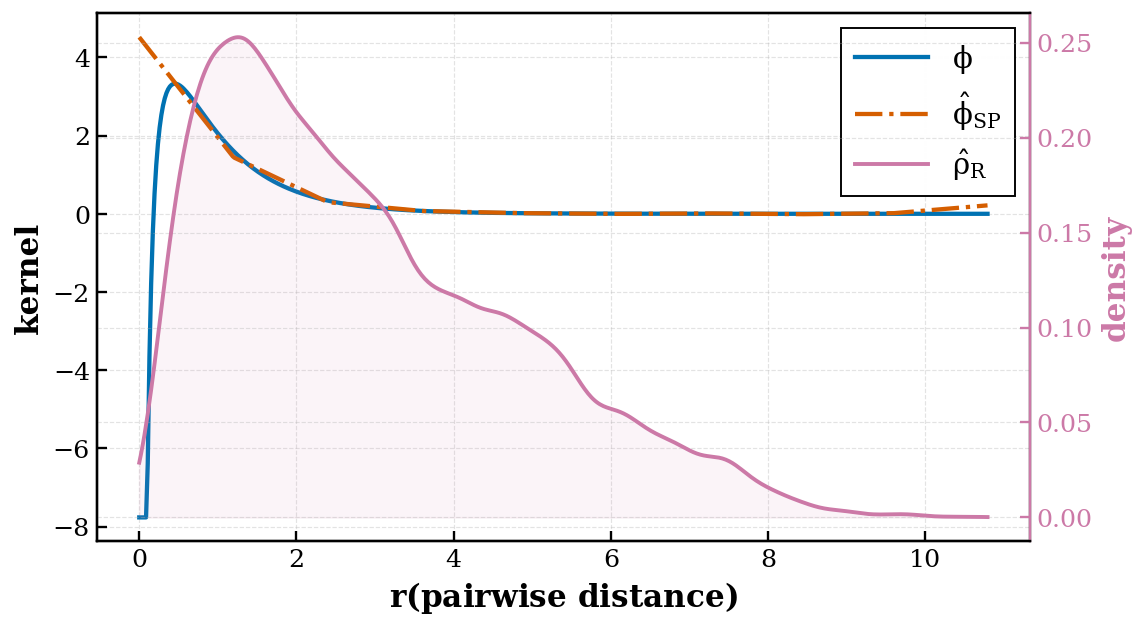

In [22]:
viz = AlgorithmComparison()

fig_kernel_compare = viz.plot_kernel_algorithm_comparison(
    r_grid=train_r_grid,
    true_kernel=true_phi,
    learned_models=LEARNED_MODELS,
    train_density=train_density,
    labels={
        "x_label": r"$r$(pairwise distance)",
        "y_label": "kernel",
        "y2_label": "density",
        "density_label": r"$\hat{\rho}_R$",
        "true_label": r"$\phi$",
        "learned_labels": {
            "nonparametric_f": r"$\hat{\phi}$_{NP} $f$",
            "parametric_f": r"$\hat{\phi}_{SP}$",
        },
        "legend_loc": "best",
    },
)

figure_repo.save(
    fig_kernel_compare,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_kernel_phi_parametric_f_basis2",
)
fig_kernel_compare

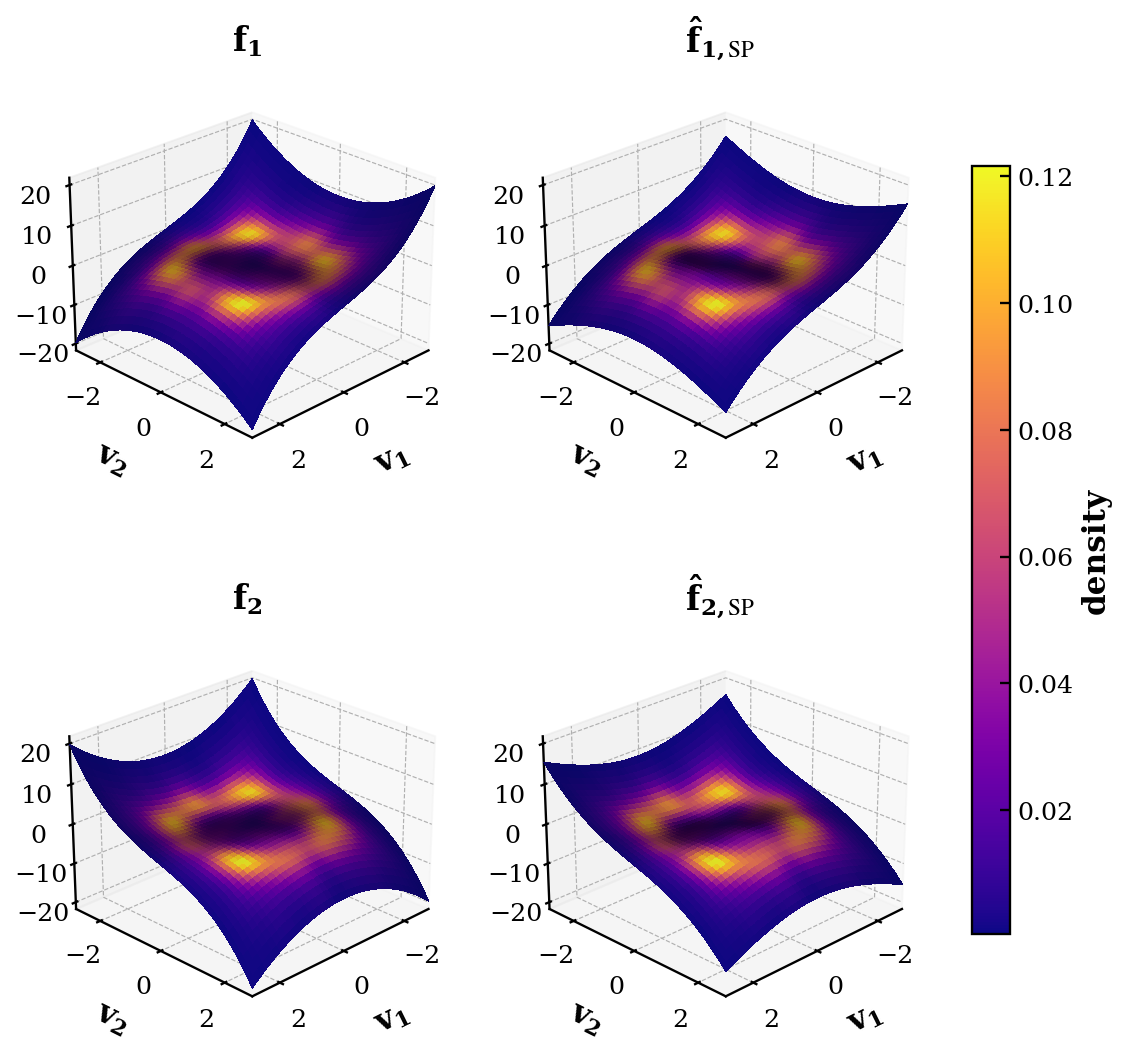

In [23]:
fig_f_compare = viz.plot_environment_surfaces_2d(
    learned_models=LEARNED_MODELS,
    z1_grid=z1_grid,
    z2_grid=z2_grid,
    reference_density=density_grid,
    true_env=true_f,
    environment_variable="v",
    zlim_mode="joint",
    labels={
        "x1_label": r"$v_1$",
        "x2_label": r"$v_2$",
        "true_comp_labels": [
            r"$f_{1}$",
            r"$f_{2}$",
        ],
        "learned_comp_labels": {
            "nonparametric_f": [
                r"$\hat f_{{1},{\mathrm{NP}}}$",
                r"$\hat f_{{2},{\mathrm{NP}}}$",
            ],
            "parametric_f": [
                r"$\hat f_{{1},{\mathrm{SP}}}$",
                r"$\hat f_{{2},{\mathrm{SP}}}$",
            ],
        },
        "colorbar_label": "density",#r"$\rho_v$",
        "show_zlabel": False,
    },
)

figure_repo.save(
    fig_f_compare,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="learned_f_parametric_f_basis2",
)
fig_f_compare

In [24]:
# Helper to extract one trajectory
def extract_single_trajectory(dataset, artifact, m: int = 0):
    """
    Convert saved layout:
        dataset.X[m]      : (L, N, D)
        artifact.X_hat[m] : (L, N, D)

    to visualization layout:
        X_true : (N, D, L)
        X_hat  : (N, D, L)

    V_true and V_hat are None for first-order systems.
    """
    t = dataset.t

    X_true = np.transpose(dataset.X[m], (1, 2, 0))
    X_hat = np.transpose(artifact.X_hat[m], (1, 2, 0))

    if dataset.V is None:
        V_true = None
    else:
        V_true = np.transpose(dataset.V[m], (1, 2, 0))

    if artifact.V_hat is None:
        V_hat = None
    else:
        V_hat = np.transpose(artifact.V_hat[m], (1, 2, 0))

    return t, X_true, V_true, X_hat, V_hat

PosixPath('./artifacts/spp/limitation/parameter_misspecification/figures/spp/figures/parameter_misspecification_parametric_f_basis2/parametric_f_train_full_coordinate_d2.png')

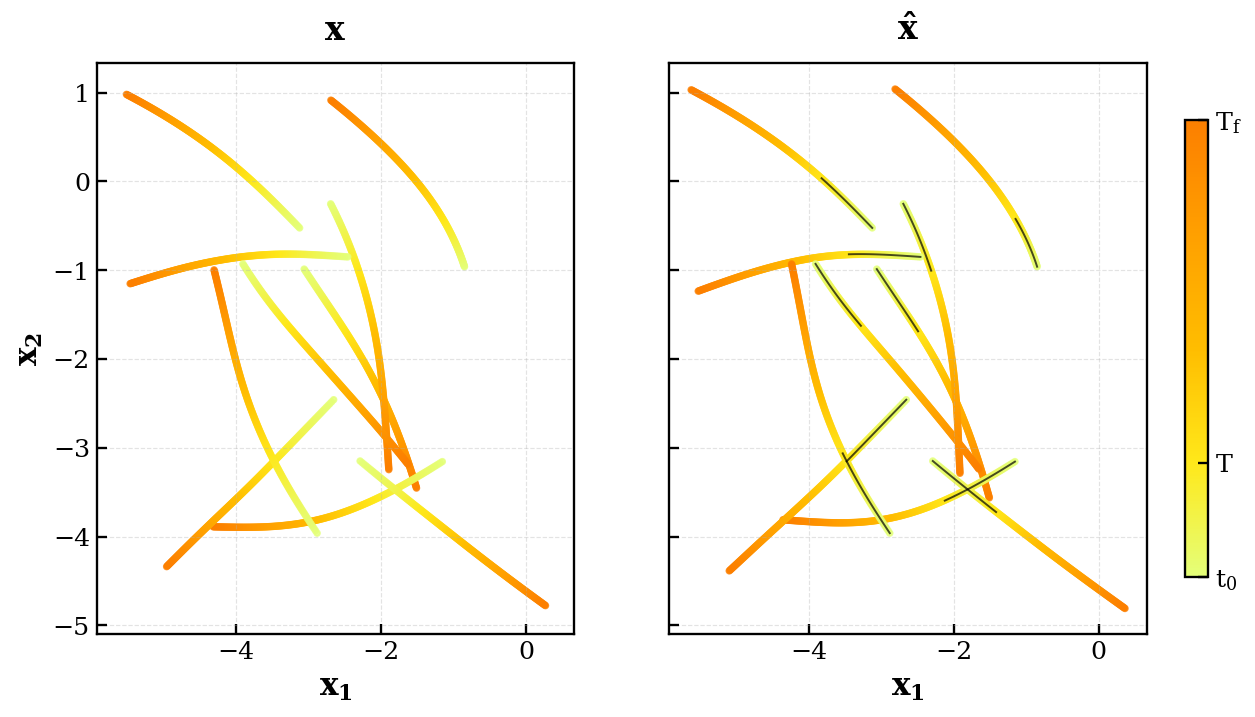

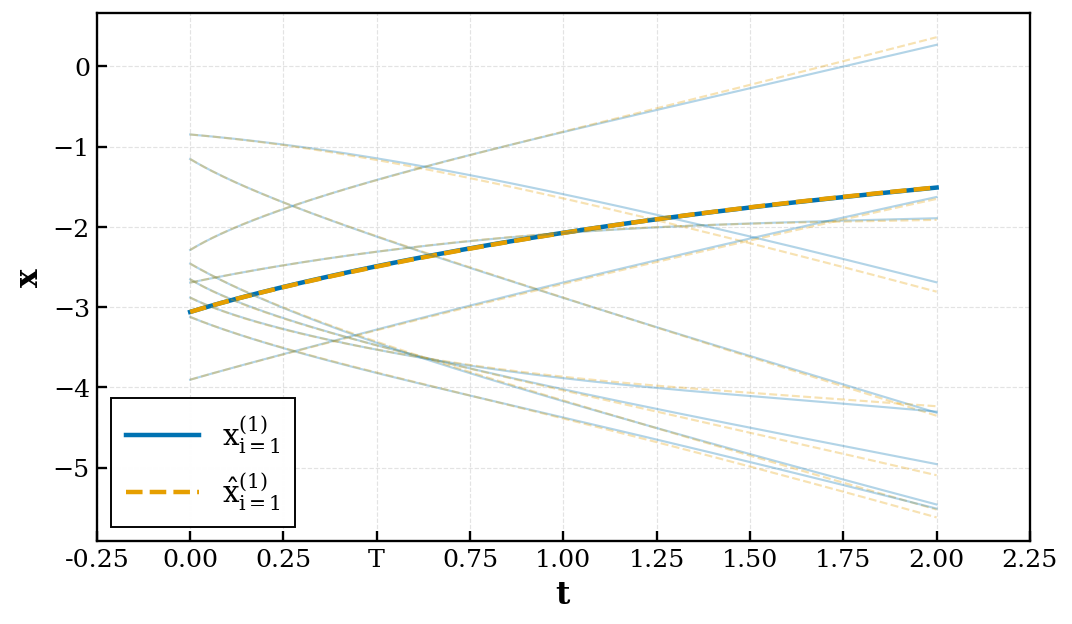

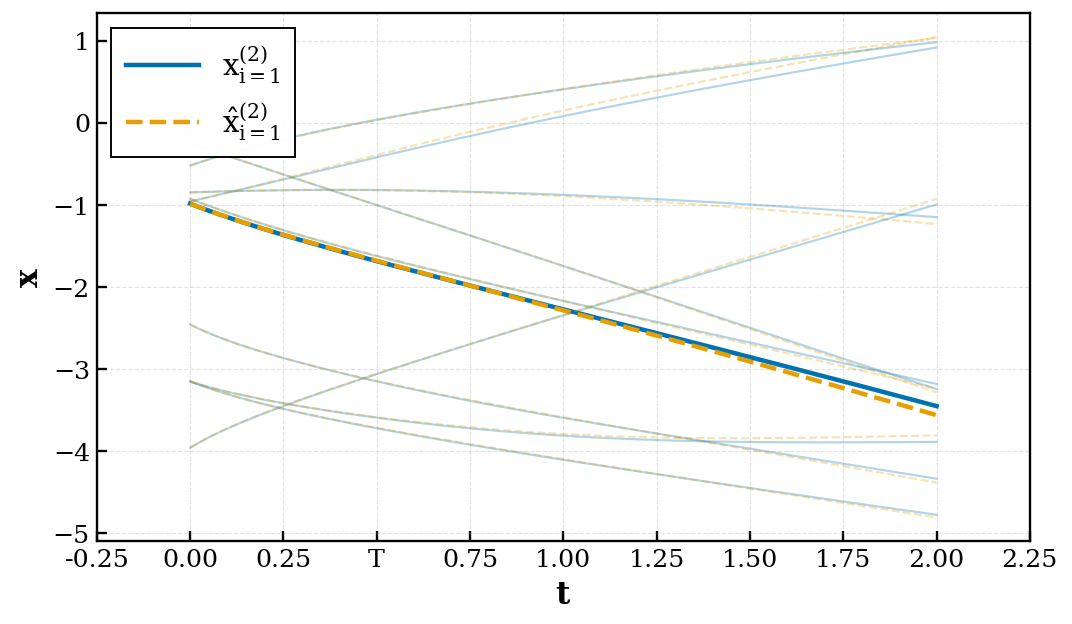

In [25]:
from ips_learning.visualization.trajectories import TrajectoryVisualizer

viz = TrajectoryVisualizer()




t, X_true, V_true, X_hat, V_hat = extract_single_trajectory(
    train_dataset,
    rollout_train_full,
    m=0,
)

fig_phase_train = viz.plot_true_vs_learned_phase_portrait(
    t=t,
    X_true=X_true,
    X_hat=X_hat,
    train_fit_end_pt=FIT_END_TIME,
    train_fit_mark=True,
    title_true=r"$x$",
    title_hat=r"$\hat{x}$",
)

figure_repo.save(
    fig_phase_train,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name=f"{algorithm}_train_full_phase_portrait",
    close=False,
)

fig_coord_train = viz.plot_true_vs_learned_coordinate(
    t_true=t,
    X_true=X_true,
    t_hat=rollout_train_full.t,
    X_hat=X_hat,
    component=0,
    train_fit_end_pt=FIT_END_TIME,
    highlight_agent=0,
    title=None,#rf"Levi: $x_0 \in M_{{\mathrm{{train}}}},\ t \in [t_0,T_f]$ ({algorithm})",
)

figure_repo.save(
    fig_coord_train,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name=f"{algorithm}_train_full_coordinate_d1",
    close=False,
)

fig_coord_train = viz.plot_true_vs_learned_coordinate(
    t_true=t,
    X_true=X_true,
    t_hat=rollout_train_full.t,
    X_hat=X_hat,
    component=1,
    train_fit_end_pt=FIT_END_TIME,
    highlight_agent=0,
    title=None,#rf"Levi: $x_0 \in M_{{\mathrm{{train}}}},\ t \in [t_0,T_f]$ ({algorithm})",
)

figure_repo.save(
    fig_coord_train,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name=f"{algorithm}_train_full_coordinate_d2",
    close=False,
)

In [26]:
# trajectory data plot.

# # bases vs Ef, E_\phi
#IC show f, \phi with the sample data

